In [35]:

import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU: Tesla T4


In [36]:
import matplotlib.pyplot as plt
from PIL import Image
import random

IMAGE_PATH = os.path.join(DATASET_PATH, "img_align_celeba")

image_files = [
    f for f in os.listdir(IMAGE_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total Images:", len(image_files))

samples = random.sample(image_files, min(16, len(image_files)))

plt.figure(figsize=(10, 10))

for i, file in enumerate(samples):
    img = Image.open(os.path.join(IMAGE_PATH, file)).convert("RGB")
    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()


Total Images: 0


<Figure size 1000x1000 with 0 Axes>

In [37]:
import os

DATASET_PATH = "/kaggle/input/datasets/jessicali9530/celeba-dataset"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 3:
        print(f"\nFolder: {root}")
        print("Subfolders:", dirs[:10])
        print("Files:", files[:10])


Folder: /kaggle/input/datasets/jessicali9530/celeba-dataset
Subfolders: ['img_align_celeba']
Files: ['list_attr_celeba.csv', 'list_bbox_celeba.csv', 'list_eval_partition.csv', 'list_landmarks_align_celeba.csv']

Folder: /kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba
Subfolders: ['img_align_celeba']
Files: []

Folder: /kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba
Subfolders: []
Files: ['000001.jpg', '000002.jpg', '000003.jpg', '000004.jpg', '000005.jpg', '000006.jpg', '000007.jpg', '000008.jpg', '000009.jpg', '000010.jpg']


In [38]:
image_extensions = (".jpg", ".jpeg", ".png")

image_paths = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, file))

print("Total Images Found:", len(image_paths))

if image_paths:
    print("\nFirst 10 Images:")
    for path in image_paths[:10]:
        print(path)
else:
    print("No images found. Check dataset directory.")


Total Images Found: 202599

First 10 Images:
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000001.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000002.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000003.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000004.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000005.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000006.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000007.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000008.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba/000009.jpg
/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_cel

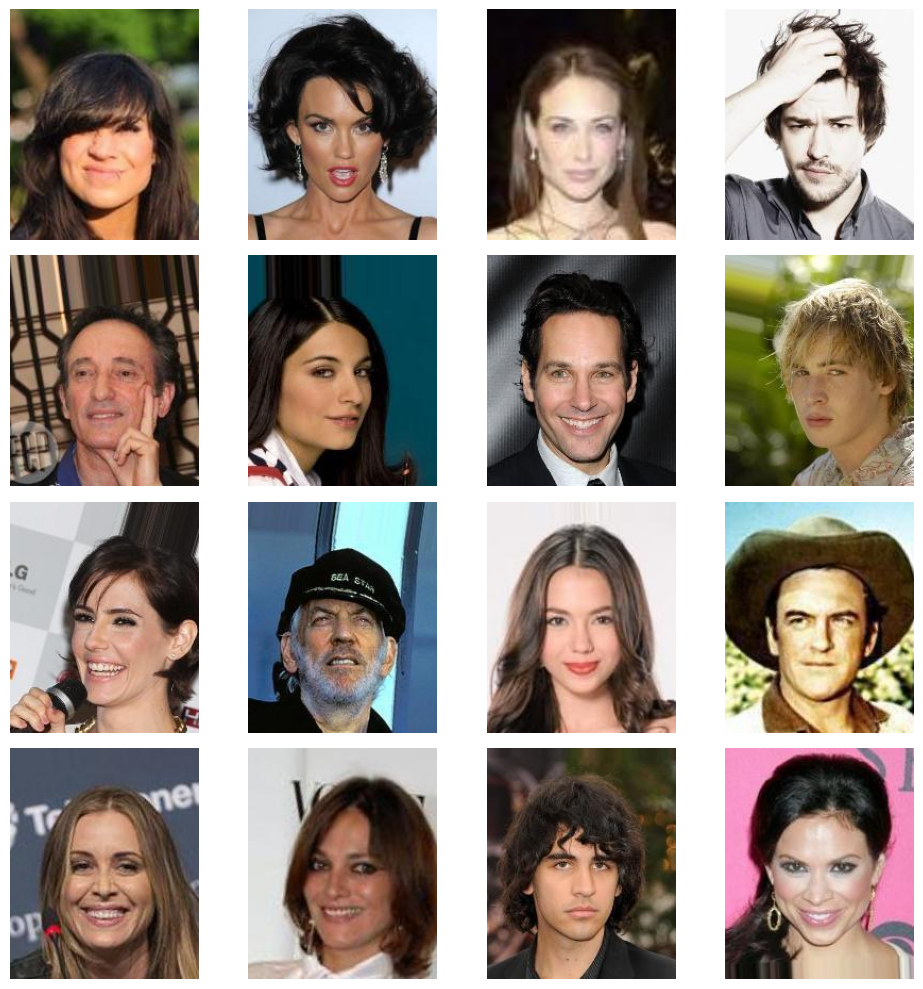

In [39]:

import matplotlib.pyplot as plt
from PIL import Image
import random

samples = random.sample(image_paths, min(16, len(image_paths)))

plt.figure(figsize=(10, 10))

for i, path in enumerate(samples):
    image = Image.open(path).convert("RGB")

    plt.subplot(4, 4, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [40]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGE_SIZE = 64
BATCH_SIZE = 128

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

class CelebADataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

dataset = CelebADataset(image_paths, transform=transform)

print("Dataset Size:", len(dataset))
print("Image Shape:", dataset[0].shape)


Dataset Size: 202599
Image Shape: torch.Size([3, 64, 64])


In [43]:

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

real_images = next(iter(dataloader))

print("Batch Shape:", real_images.shape)
print("Minimum Pixel Value:", real_images.min().item())
print("Maximum Pixel Value:", real_images.max().item())


Batch Shape: torch.Size([128, 3, 64, 64])
Minimum Pixel Value: -1.0
Maximum Pixel Value: 1.0


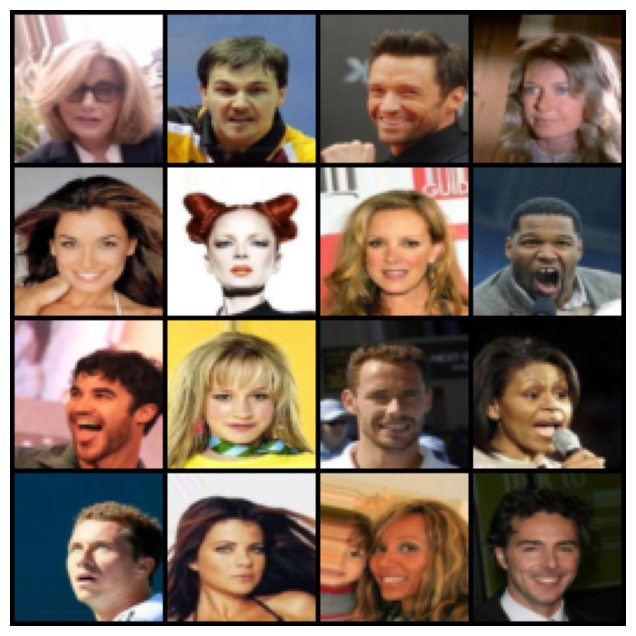

In [44]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

images = next(iter(dataloader))

grid = make_grid(
    images[:16],
    nrow=4,
    normalize=True,
    value_range=(-1, 1)
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()


In [45]:

import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [46]:

import torch.nn as nn

LATENT_DIM = 100
FEATURES_G = 64

class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()

        self.model = nn.Sequential(
            nn.ConvTranspose2d(LATENT_DIM, FEATURES_G * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(FEATURES_G * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(FEATURES_G * 8, FEATURES_G * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(FEATURES_G * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(FEATURES_G * 4, FEATURES_G * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(FEATURES_G * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(FEATURES_G * 2, FEATURES_G, 4, 2, 1, bias=False),
            nn.BatchNorm2d(FEATURES_G),
            nn.ReLU(True),

            nn.ConvTranspose2d(FEATURES_G, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.model(x)

generator = Generator().to(DEVICE)

print(generator)


Generator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)

In [47]:

noise = torch.randn(16, LATENT_DIM, 1, 1, device=DEVICE)

fake_images = generator(noise)

print("Generated Images Shape:", fake_images.shape)
print("Min Value:", fake_images.min().item())
print("Max Value:", fake_images.max().item())


Generated Images Shape: torch.Size([16, 3, 64, 64])
Min Value: -0.9999474883079529
Max Value: 0.9999181628227234


In [48]:

FEATURES_D = 64

class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, FEATURES_D, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(FEATURES_D, FEATURES_D * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(FEATURES_D * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(FEATURES_D * 2, FEATURES_D * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(FEATURES_D * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(FEATURES_D * 4, FEATURES_D * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(FEATURES_D * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(FEATURES_D * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x).view(-1)

discriminator = Discriminator().to(DEVICE)

print(discriminator)


Discriminator(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)


In [49]:

predictions = discriminator(fake_images)

print("Output Shape:", predictions.shape)
print("Predictions:", predictions[:5].detach().cpu())


Output Shape: torch.Size([16])
Predictions: tensor([0.4008, 0.4715, 0.4910, 0.3251, 0.3209])


In [53]:

print("DEVICE:", DEVICE)
print("DATASET SIZE:", len(dataset))
print("DATALOADER BATCHES:", len(dataloader))
print("BATCH SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS)
print("GENERATOR:", next(generator.parameters()).device)
print("DISCRIMINATOR:", next(discriminator.parameters()).device)


DEVICE: cuda
DATASET SIZE: 202599
DATALOADER BATCHES: 1582
BATCH SIZE: 128
EPOCHS: 50
GENERATOR: cuda:0
DISCRIMINATOR: cuda:0


In [54]:

import time

print("Loading batch...", flush=True)

start = time.time()
real_images = next(iter(dataloader))

print("Batch loaded:", real_images.shape, flush=True)
print("Loading time:", round(time.time() - start, 2), flush=True)

real_images = real_images.to(DEVICE)
batch_size = real_images.size(0)

real_labels = torch.ones(batch_size, device=DEVICE)
fake_labels = torch.zeros(batch_size, device=DEVICE)

print("Training Discriminator...", flush=True)

optimizer_D.zero_grad()

real_output = discriminator(real_images)
real_loss = criterion(real_output, real_labels)

noise = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
fake_images = generator(noise)

fake_output = discriminator(fake_images.detach())
fake_loss = criterion(fake_output, fake_labels)

d_loss = real_loss + fake_loss
d_loss.backward()
optimizer_D.step()

print("D Loss:", d_loss.item(), flush=True)

print("Training Generator...", flush=True)

optimizer_G.zero_grad()

output = discriminator(fake_images)
g_loss = criterion(output, real_labels)

g_loss.backward()
optimizer_G.step()

print("G Loss:", g_loss.item(), flush=True)

print("One training step completed!", flush=True)


Loading batch...
Batch loaded: torch.Size([128, 3, 64, 64])
Loading time: 10.48
Training Discriminator...
D Loss: 0.6795094013214111
Training Generator...
G Loss: 3.0613439083099365
One training step completed!


In [57]:

from tqdm.auto import tqdm
import os
import torch
import torchvision.utils as vutils

EPOCHS = 10

G_losses = []
D_losses = []

OUTPUT_DIR = "/kaggle/working/generated_images"
CHECKPOINT_DIR = "/kaggle/working/checkpoints"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=DEVICE)

print("Training setup completed!")


Training setup completed!


In [58]:
import torch.optim as optim

LEARNING_RATE = 0.0002
BETA1 = 0.5
BETA2 = 0.999

criterion = nn.BCELoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2)
)

print("GAN Training Components Ready")


GAN Training Components Ready


In [60]:

for epoch in range(EPOCHS):

    generator.train()
    discriminator.train()

    running_g_loss = 0
    running_d_loss = 0

    progress_bar = tqdm(
        dataloader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for real_images in progress_bar:

        real_images = real_images.to(DEVICE)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, device=DEVICE)
        fake_labels = torch.zeros(batch_size, device=DEVICE)

        optimizer_D.zero_grad(set_to_none=True)

        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, LATENT_DIM, 1, 1, device=DEVICE)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_D.step()

        optimizer_G.zero_grad(set_to_none=True)

        output = discriminator(fake_images)
        g_loss = criterion(output, real_labels)

        g_loss.backward()
        optimizer_G.step()

        running_g_loss += g_loss.item()
        running_d_loss += d_loss.item()

        progress_bar.set_postfix({
            "D Loss": f"{d_loss.item():.4f}",
            "G Loss": f"{g_loss.item():.4f}"
        })

    avg_g_loss = running_g_loss / len(dataloader)
    avg_d_loss = running_d_loss / len(dataloader)

    G_losses.append(avg_g_loss)
    D_losses.append(avg_d_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f}"
    )

    generator.eval()

    with torch.no_grad():
        generated = generator(fixed_noise).cpu()

    vutils.save_image(
        generated,
        f"{OUTPUT_DIR}/epoch_{epoch+1:03d}.png",
        normalize=True,
        nrow=8
    )

    torch.save({
        "epoch": epoch + 1,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "G_losses": G_losses,
        "D_losses": D_losses
    }, f"{CHECKPOINT_DIR}/latest_checkpoint.pth")

    print(f"Epoch {epoch+1} saved successfully!")


Epoch 1/10:   0%|          | 0/1582 [00:00<?, ?it/s]

Epoch 1/10 | D Loss: 0.7190 | G Loss: 3.2706
Epoch 1 saved successfully!


Epoch 2/10:   0%|          | 0/1582 [00:00<?, ?it/s]

Epoch 2/10 | D Loss: 0.6370 | G Loss: 3.1533
Epoch 2 saved successfully!


Epoch 3/10:   0%|          | 0/1582 [00:00<?, ?it/s]

Epoch 3/10 | D Loss: 0.5648 | G Loss: 3.2327
Epoch 3 saved successfully!


... (12 outputs left out)

Epoch 9/10 | D Loss: 0.3784 | G Loss: 3.9297
Epoch 9 saved successfully!


Epoch 10/10:   0%|          | 0/1582 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3737f2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab3737f2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 10/10 | D Loss: 0.3506 | G Loss: 4.0489
Epoch 10 saved successfully!


In [61]:
print("Generator Losses:", len(G_losses))
print("Discriminator Losses:", len(D_losses))

print("G Loss:", G_losses[:5])
print("D Loss:", D_losses[:5])

Generator Losses: 10
Discriminator Losses: 10
G Loss: [3.2706350646677573, 3.153334904636354, 3.232695698959449, 3.3886298834170803, 3.5178287052225636]
D Loss: [0.7190067142662598, 0.6370112648994372, 0.5648253788858388, 0.5240151640757749, 0.4744790585761049]


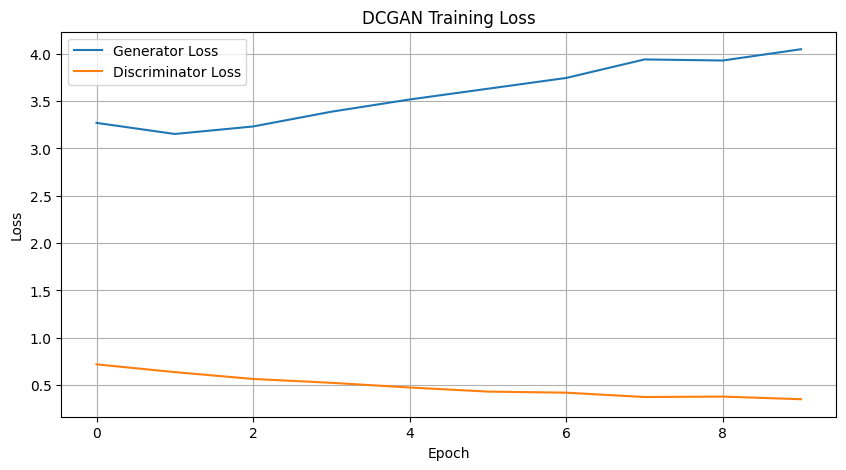

In [62]:

plt.figure(figsize=(10, 5))

plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid()
plt.show()

G_losses = []
D_losses = []

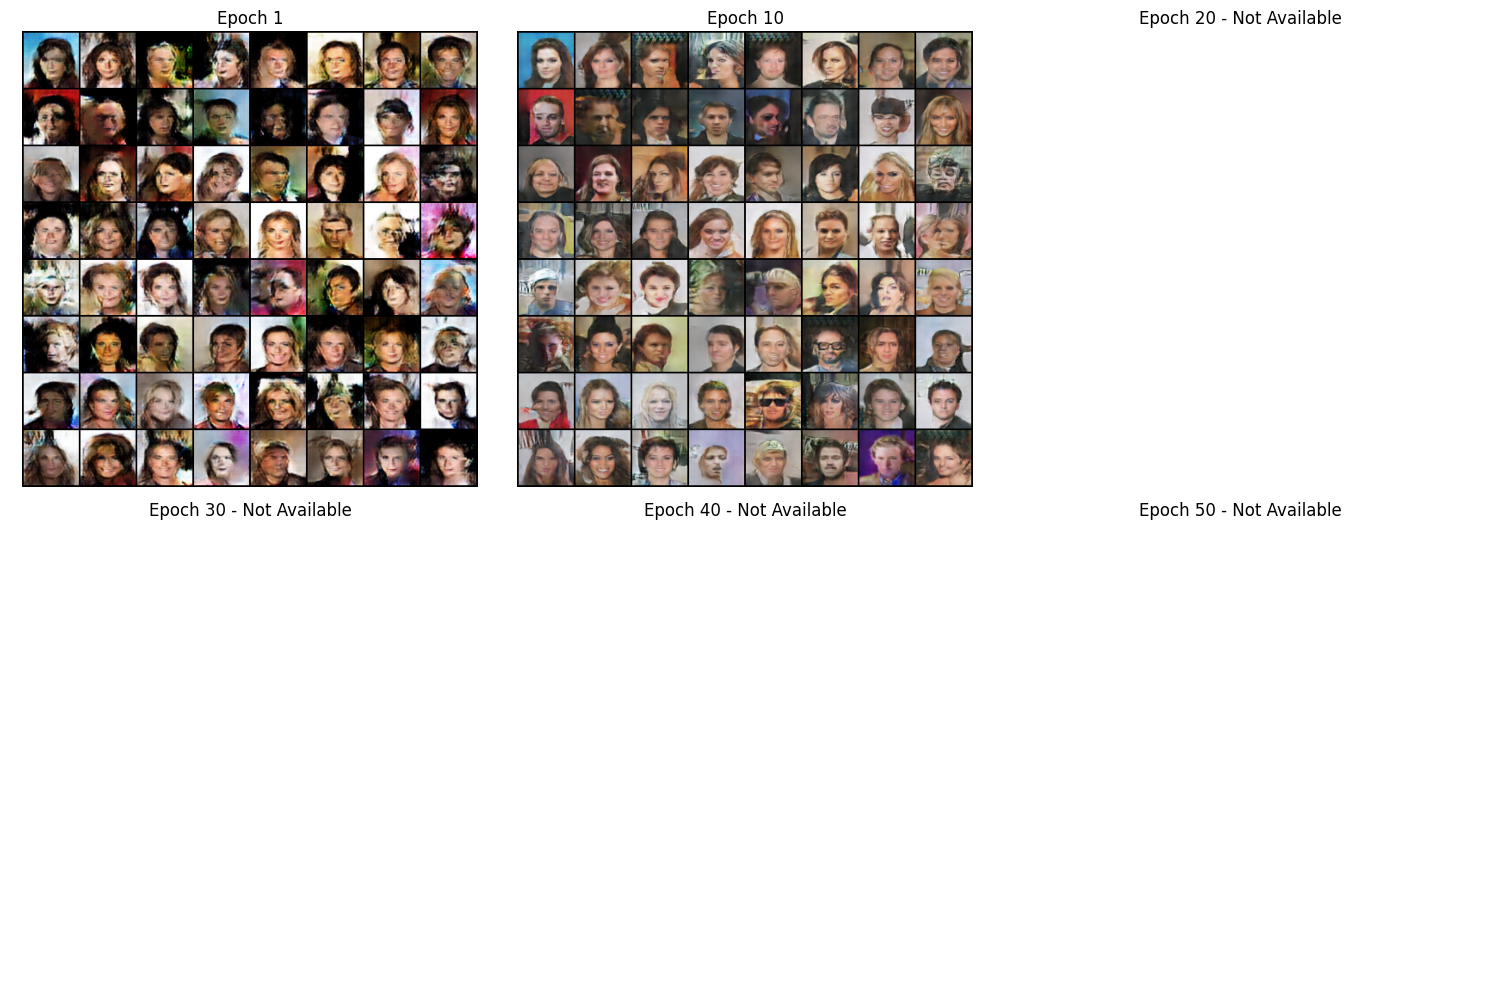

In [64]:

from PIL import Image
import matplotlib.pyplot as plt
import os

epochs_to_compare = [1, 10, 20, 30, 40, 50]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, epoch in zip(axes.flatten(), epochs_to_compare):

    image_path = f"{OUTPUT_DIR}/epoch_{epoch:03d}.png"

    if os.path.exists(image_path):
        image = Image.open(image_path)
        ax.imshow(image)
        ax.set_title(f"Epoch {epoch}")
    else:
        ax.set_title(f"Epoch {epoch} - Not Available")

    ax.axis("off")

plt.tight_layout()
plt.show()


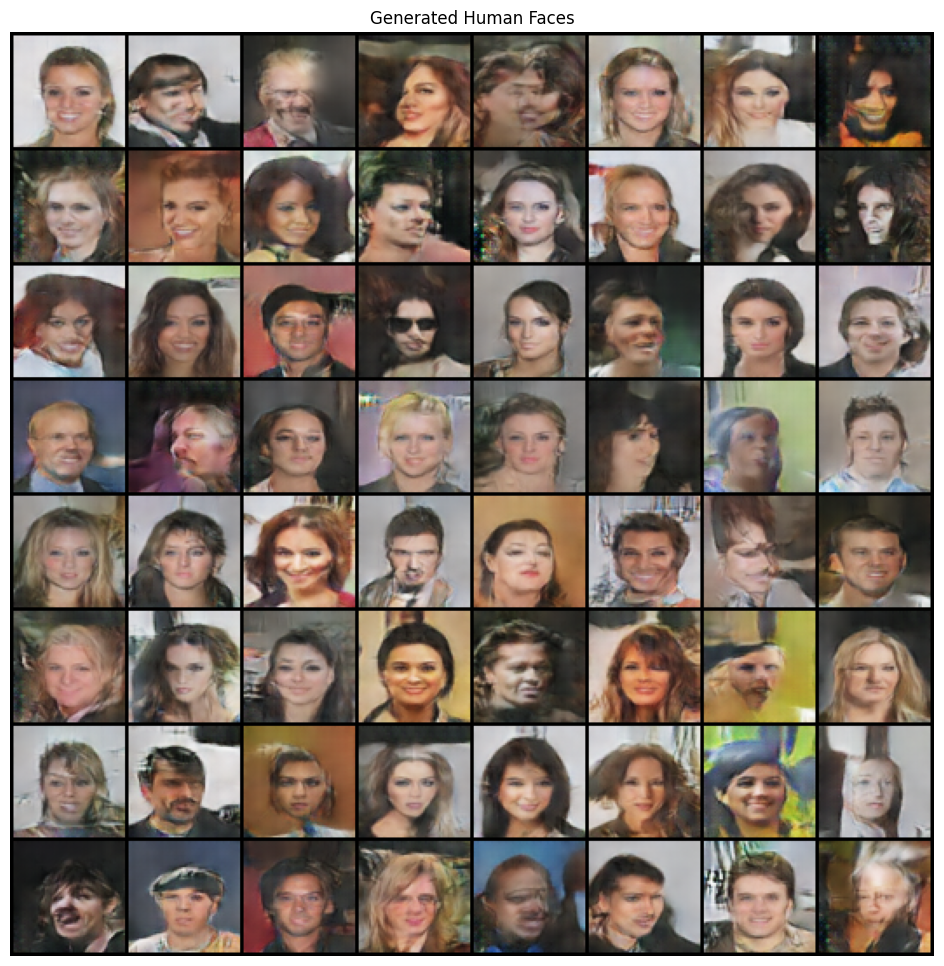

In [65]:

generator.eval()

with torch.no_grad():
    random_noise = torch.randn(64, LATENT_DIM, 1, 1, device=DEVICE)
    generated_faces = generator(random_noise).cpu()

grid = vutils.make_grid(
    generated_faces,
    nrow=8,
    normalize=True,
    value_range=(-1, 1)
)

plt.figure(figsize=(12, 12))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Generated Human Faces")
plt.show()


In [66]:

torch.save(
    generator.state_dict(),
    "/kaggle/working/generator_final.pth"
)

torch.save(
    discriminator.state_dict(),
    "/kaggle/working/discriminator_final.pth"
)

print("Models saved successfully!")


Models saved successfully!


In [67]:
print("Completed Epochs:", len(G_losses))
print("Generator Loss Records:", len(G_losses))
print("Discriminator Loss Records:", len(D_losses))

print("Saved Images:", len([
    f for f in os.listdir(OUTPUT_DIR)
    if f.endswith(".png")
]))

print("Checkpoint Exists:", os.path.exists(
    f"{CHECKPOINT_DIR}/latest_checkpoint.pth"
))


Completed Epochs: 0
Generator Loss Records: 0
Discriminator Loss Records: 0
Saved Images: 10
Checkpoint Exists: True


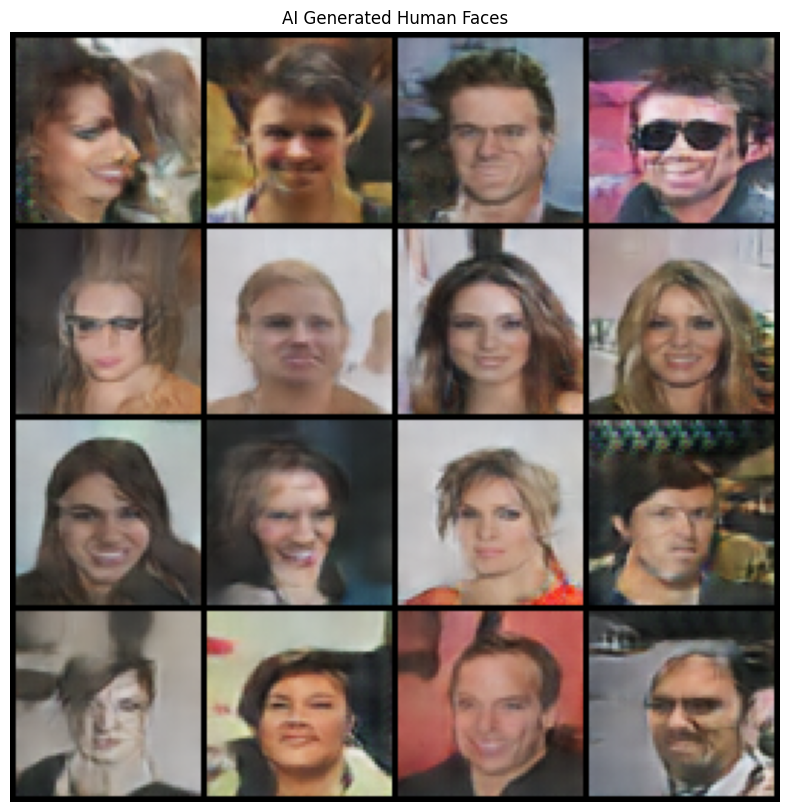

In [68]:

import torch
import matplotlib.pyplot as plt
import torchvision.utils as vutils

def generate_faces(num_faces=16):
    generator.eval()

    with torch.no_grad():
        noise = torch.randn(
            num_faces,
            LATENT_DIM,
            1,
            1,
            device=DEVICE
        )

        fake_faces = generator(noise).cpu()

    grid = vutils.make_grid(
        fake_faces,
        nrow=4,
        normalize=True,
        value_range=(-1, 1)
    )

    plt.figure(figsize=(10, 10))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.title("AI Generated Human Faces")
    plt.show()

    return fake_faces

generated_faces = generate_faces(16)


In [69]:

import os
from torchvision.utils import save_image

GENERATED_DIR = "/kaggle/working/final_generated_faces"

os.makedirs(GENERATED_DIR, exist_ok=True)

save_image(
    generated_faces,
    f"{GENERATED_DIR}/generated_faces.png",
    normalize=True,
    value_range=(-1, 1),
    nrow=4
)

print("Generated images saved!")


Generated images saved!


In [70]:

!pip install torchmetrics torch-fidelity


In [71]:

from torchmetrics.image.fid import FrechetInceptionDistance

fid_metric = FrechetInceptionDistance(
    feature=2048,
    normalize=False
).to(DEVICE)

print("FID Metric Ready")


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 488MB/s]


FID Metric Ready


In [72]:

from tqdm.auto import tqdm

generator.eval()

NUM_FID_IMAGES = 2000
fid_batch_size = 64

with torch.no_grad():

    for start in tqdm(range(0, NUM_FID_IMAGES, fid_batch_size)):

        current_batch = min(
            fid_batch_size,
            NUM_FID_IMAGES - start
        )

        real_images = next(iter(dataloader)).to(DEVICE)

        if real_images.size(0) < current_batch:
            current_batch = real_images.size(0)

        real_images = real_images[:current_batch]

        noise = torch.randn(
            current_batch,
            LATENT_DIM,
            1,
            1,
            device=DEVICE
        )

        fake_images = generator(noise)

        real_uint8 = (
            ((real_images + 1) * 127.5)
            .clamp(0, 255)
            .to(torch.uint8)
        )

        fake_uint8 = (
            ((fake_images + 1) * 127.5)
            .clamp(0, 255)
            .to(torch.uint8)
        )

        fid_metric.update(real_uint8, real=True)
        fid_metric.update(fake_uint8, real=False)

fid_score = fid_metric.compute()

print("FID Score:", fid_score.item())


  0%|          | 0/32 [00:00<?, ?it/s]

FID Score: 50.513023376464844


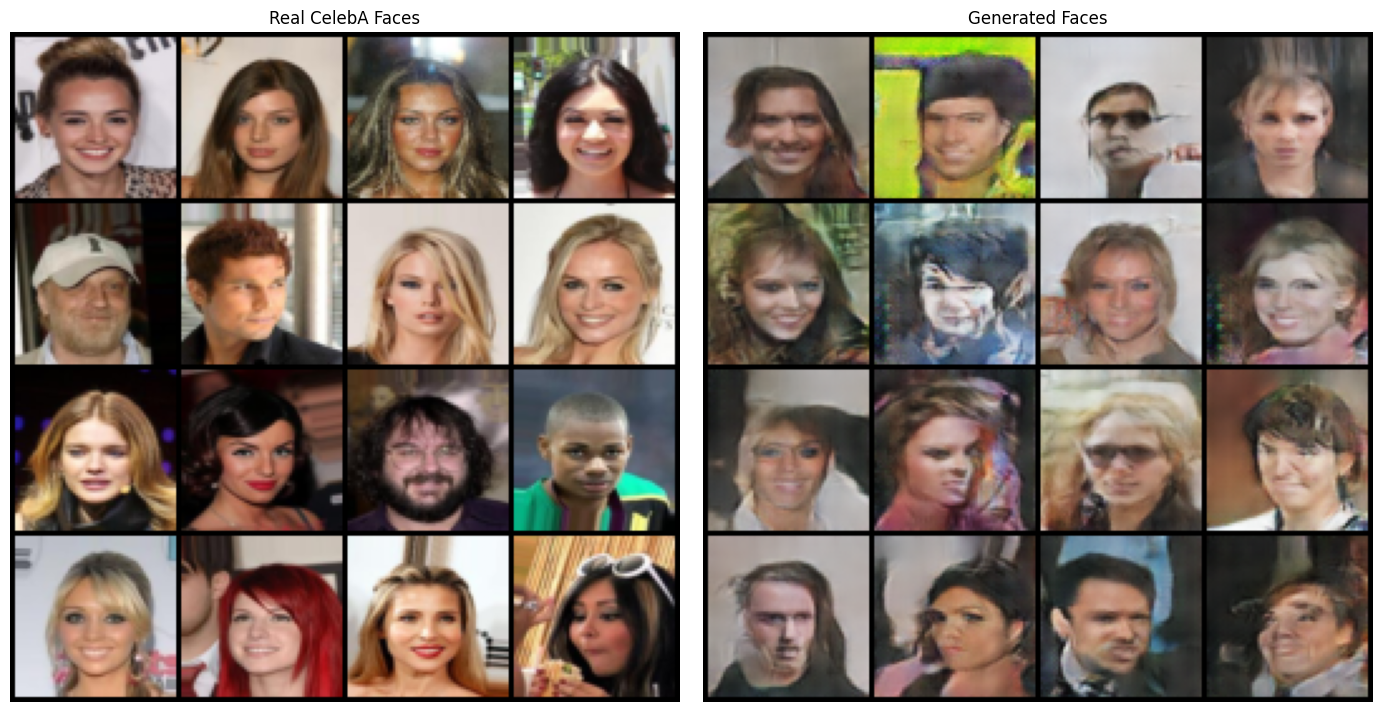

In [74]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

generator.eval()

real_images = next(iter(dataloader))[:16].to(DEVICE)

noise = torch.randn(16, LATENT_DIM, 1, 1, device=DEVICE)

with torch.no_grad():
    fake_images = generator(noise)

real_grid = vutils.make_grid(
    real_images,
    nrow=4,
    normalize=True,
    value_range=(-1, 1)
)

fake_grid = vutils.make_grid(
    fake_images,
    nrow=4,
    normalize=True,
    value_range=(-1, 1)
)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(real_grid.permute(1, 2, 0).cpu())
plt.title("Real CelebA Faces")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(fake_grid.permute(1, 2, 0).cpu())
plt.title("Generated Faces")
plt.axis("off")

plt.tight_layout()
plt.show()

In [77]:
import os
import torch

CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_GENERATOR_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_generator.pth"
)

FINAL_GENERATOR_PATH = os.path.join(
    CHECKPOINT_DIR,
    "final_generator.pth"
)

torch.save(
    generator.state_dict(),
    FINAL_GENERATOR_PATH
)

if os.path.exists(BEST_GENERATOR_PATH):
    previous = torch.load(
        BEST_GENERATOR_PATH,
        map_location=DEVICE,
        weights_only=False
    )
    best_fid = previous["fid"]
else:
    best_fid = float("inf")

if fid_score < best_fid:
    torch.save(
        {
            "generator_state_dict": generator.state_dict(),
            "fid": fid_score,
            "epoch": len(G_losses)
        },
        BEST_GENERATOR_PATH
    )
    print("New Best Generator Saved!")
else:
    print("Previous Best Generator Preserved.")

print("Final Generator:", FINAL_GENERATOR_PATH)
print("Best Generator:", BEST_GENERATOR_PATH)
print("Current FID:", fid_score)

New Best Generator Saved!
Final Generator: /kaggle/working/checkpoints/final_generator.pth
Best Generator: /kaggle/working/checkpoints/best_generator.pth
Current FID: tensor(50.5130, device='cuda:0')


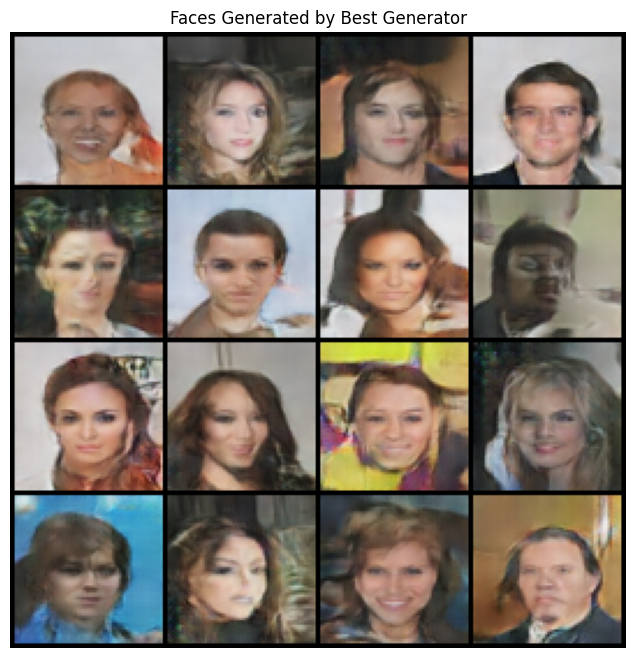

In [78]:
checkpoint = torch.load(
    BEST_GENERATOR_PATH,
    map_location=DEVICE,
    weights_only=False
)

generator.load_state_dict(checkpoint["generator_state_dict"])
generator.eval()

noise = torch.randn(
    16,
    LATENT_DIM,
    1,
    1,
    device=DEVICE
)

with torch.no_grad():
    generated_faces = generator(noise)

generated_grid = vutils.make_grid(
    generated_faces,
    nrow=4,
    normalize=True,
    value_range=(-1, 1)
)

plt.figure(figsize=(8, 8))
plt.imshow(generated_grid.permute(1, 2, 0).cpu())
plt.title("Faces Generated by Best Generator")
plt.axis("off")
plt.show()

In [79]:
GENERATED_DIR = "/kaggle/working/generated_faces"
os.makedirs(GENERATED_DIR, exist_ok=True)

for i, face in enumerate(generated_faces):
    vutils.save_image(
        face,
        os.path.join(GENERATED_DIR, f"face_{i+1}.png"),
        normalize=True,
        value_range=(-1, 1)
    )

print("Generated faces saved successfully.")

Generated faces saved successfully.


In [81]:
!pip install -q gradio

In [84]:
import os
import tempfile

import gradio as gr
import numpy as np
import torch
from PIL import Image


# ---------- Generation ----------
def generate_interface(num_images, seed, randomize):
    generator.eval()

    if randomize or seed is None:
        seed = int(torch.randint(0, 2**31 - 1, (1,)).item())
    seed = int(seed)

    g = torch.Generator(device="cpu").manual_seed(seed)
    noise = torch.randn(int(num_images), LATENT_DIM, 1, 1, generator=g).to(DEVICE)

    with torch.no_grad():
        images = generator(noise)

    images = ((images + 1) / 2).clamp(0, 1)

    results, paths = [], []
    tmp_dir = tempfile.mkdtemp()
    for i, img in enumerate(images):
        arr = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
        pil = Image.fromarray(arr)
        results.append(pil)
        p = os.path.join(tmp_dir, f"face_{seed}_{i + 1}.png")
        pil.save(p)
        paths.append(p)

    status = f"✅ Generated {int(num_images)} faces  |  Seed: {seed}"
    return results, paths, status, seed


# ---------- Theme & CSS ----------
theme = gr.themes.Soft(
    primary_hue="violet",
    secondary_hue="indigo",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "sans-serif"],
).set(
    body_background_fill="#0b0f1a",
    block_background_fill="#131a2b",
    block_border_width="1px",
    block_border_color="#26304a",
    block_radius="16px",
    button_primary_background_fill="linear-gradient(90deg,#7c3aed,#4f46e5)",
    button_primary_text_color="white",
)

css = """
.gradio-container {max-width: 1200px !important; margin: auto;}
#header {text-align:center; padding: 28px 10px 10px;}
#header h1 {
    font-size: 2.4rem; font-weight: 800; margin: 0;
    background: linear-gradient(90deg,#a78bfa,#60a5fa);
    -webkit-background-clip: text; -webkit-text-fill-color: transparent;
}
#header p {color:#94a3b8; margin-top:8px; font-size:1.05rem;}
#gen-btn {height: 52px; font-size: 1.1rem; font-weight: 700; border-radius: 12px;}
#status {text-align:center; color:#a5b4fc; font-weight:600;}
footer {display:none !important;}
"""

# Gradio 6 moved theme/css from Blocks() to launch()
GRADIO_MAJOR = int(gr.__version__.split(".")[0])
blocks_kwargs = {"title": "AI Face Generator"}
launch_kwargs = {"share": True}
if GRADIO_MAJOR >= 6:
    launch_kwargs.update(theme=theme, css=css)
else:
    blocks_kwargs.update(theme=theme, css=css)


# ---------- UI ----------
with gr.Blocks(**blocks_kwargs) as demo:

    gr.HTML("""
    <div id="header">
        <h1>🧑‍🎨 AI Human Face Generator</h1>
        <p>Generate synthetic human faces using a trained DCGAN model</p>
    </div>
    """)

    with gr.Row(equal_height=False):
        with gr.Column(scale=1, min_width=300):
            gr.Markdown("### ⚙️ Settings")
            num_images = gr.Slider(1, 32, value=16, step=1, label="Number of Faces")
            randomize = gr.Checkbox(value=True, label="🎲 Random seed each time")
            seed = gr.Number(value=42, precision=0, label="Seed (for reproducible results)")
            generate_btn = gr.Button("✨ Generate Faces", variant="primary", elem_id="gen-btn")
            status = gr.Markdown("Ready.", elem_id="status")
            downloads = gr.File(label="⬇️ Download Images", file_count="multiple")
            gr.Markdown(
                "<small style='color:#64748b'>Tip: uncheck random seed and reuse a seed "
                "to reproduce the same set of faces.</small>"
            )

        with gr.Column(scale=3):
            gallery = gr.Gallery(
                label="Generated Faces",
                columns=4,
                height="auto",
                object_fit="cover",
                preview=False,
            )

    io = dict(
        fn=generate_interface,
        inputs=[num_images, seed, randomize],
        outputs=[gallery, downloads, status, seed],
    )
    generate_btn.click(**io)
    demo.load(**io)

demo.queue().launch(**launch_kwargs)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://ae02c8474fe0864eff.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
